# resource-driving: `food_per` temporal regeneration knob

Wave-1 of the `resource-driving` branch (checkpoint 3 July 2026 §C / action C1).

`food_per` is the environmental food-regeneration **period**. Phase 2 regeneration
fires only every `food_per`-th step, and when it fires it adds `food_inc * food_per`.
So the long-run mean input rate is held fixed while the input is lumped in time —
between replenishments, agent grazing carves depletion structure that persists for
`food_per` steps instead of being erased every tick.

This notebook demonstrates two claims with explicit PASS/FAIL:
1. **`food_per=1` reproduces the baseline** (`F += food_inc` every step) bit-for-bit.
2. **`food_per=K` produces the intended sawtooth** in mean `F_env`, mean-preserving vs `food_per=1`.

In [1]:
import os, sys, subprocess
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, 'C', 'evoca.h')):
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, 'python'))

# Rebuild the C library if missing/stale so the notebook is self-contained.
src = os.path.join(ROOT, 'C', 'evoca.c')
lib = os.path.join(ROOT, 'C', 'libevoca.dylib')
if (not os.path.exists(lib)) or os.path.getmtime(lib) < os.path.getmtime(src):
    subprocess.run(['gcc', '-O2', '-Wall', '-fPIC', '-dynamiclib', '-o', lib, src],
                   cwd=ROOT, check=True)

from evoca_py import EvoCA
print('library ready')

library ready


## Helper: F driven ONLY by Phase-2 regeneration

All cells dead (no eating / tax / reproduction), no diffusion — so the F field is a
clean readout of the regeneration schedule.

In [2]:
def regen_series(food_inc, food_per, steps, N=32, F0=0.0):
    s = EvoCA()
    s.init(N, food_inc=food_inc, gdiff=0.0, food_per=food_per)
    s.state(lut='gol', egenome='uniform', egenome_value=0)
    s.set_alive_fraction(0.0)   # every cell dead -> F only changes via Phase 2
    s.set_f_all(0.0)
    s.set_F_all(F0)
    means = []
    for _ in range(steps):
        s.step()
        means.append(float(s.get_F().mean()))
    s.free()
    return np.array(means)

## Test 1 — `food_per=1` reproduces baseline bit-for-bit

A full evolving sim (eating, reproduction, mutation) run with the default init path
(no `food_per` argument, C default = 1) must be bit-for-bit identical to an explicit
`food_per=1` run. This proves the new code is a true no-op at `food_per=1`.

In [3]:
def full_sim(food_per, N=48, seed=123, n_steps=150):
    rng = np.random.default_rng(seed)
    kw = dict(food_inc=0.02, m_scale=1.2, gdiff=0.0, tax=0.01, mu_lut=0.01, mu_egenome=0.01)
    if food_per is not None:
        kw['food_per'] = food_per
    s = EvoCA(); s.init(N, **kw)
    s.set_seed(seed)
    s.state(lut='gol', egenome='uniform', egenome_value=0b000011)
    s.set_v(rng.integers(0, 2, (N, N), dtype=np.uint8))
    s.set_f_all(0.5); s.set_F_all(1.0); s.set_alive_halfplane(0)
    for _ in range(n_steps):
        s.step()
    fp = (s.get_F().tobytes(), s.get_v().tobytes(),
          s.get_alive().tobytes(), s.get_f().tobytes())
    s.free()
    return fp

fp_default  = full_sim(None)   # C/Python default -> food_per = 1
fp_explicit = full_sim(1)      # explicit food_per = 1
test1_pass = (fp_default == fp_explicit)
print('TEST 1  food_per=1 == baseline (bit-for-bit):', 'PASS' if test1_pass else 'FAIL')

TEST 1  food_per=1 == baseline (bit-for-bit): PASS


## Test 2 — `food_per=K` produces the intended sawtooth in mean `F_env`

With `food_per=1` the mean rises by `food_inc` every step (a ramp). With `food_per=K`
the mean is flat between fires and jumps by `food_inc*K` on firing steps (`step % K == 0`) —
a sawtooth whose per-period average tracks the `food_per=1` ramp (mean-preserving).

In [4]:
food_inc, K, steps = 0.01, 6, 36
m1 = regen_series(food_inc, 1, steps)
mK = regen_series(food_inc, K, steps)
t = np.arange(1, steps + 1)

# Checks:
#  (a) per-1 is the ramp F = step * food_inc (below clamp).
ramp_ok = np.allclose(m1, t * food_inc, atol=1e-6)
#  (b) per-K changes ONLY on firing steps (step % K == 0), and each firing
#      step jumps by exactly food_inc*K; all other steps are flat.
fires = (t % K == 0)
delta = np.diff(np.concatenate([[0.0], mK]))   # per-step change; delta[i] = change during step i+1
flat_ok = (np.allclose(delta[~fires], 0.0, atol=1e-7) and
           np.allclose(delta[fires], food_inc * K, atol=1e-6))
#  (c) at the end of each full period the two agree (mean-preserving).
period_ends = t % K == 0
meanpreserve_ok = np.allclose(m1[period_ends], mK[period_ends], atol=1e-6)
#  (d) per-K has strictly larger temporal variance (lumpier) than per-1.
lumpier_ok = mK.var() > m1.var()

test2_pass = bool(ramp_ok and flat_ok and meanpreserve_ok and lumpier_ok)
print('  ramp (per-1 = step*food_inc):', ramp_ok)
print('  flat between fires (per-K)  :', flat_ok)
print('  mean-preserving at periods  :', meanpreserve_ok)
print('  per-K temporally lumpier    :', lumpier_ok)
print('TEST 2  food_per=K sawtooth :', 'PASS' if test2_pass else 'FAIL')

  ramp (per-1 = step*food_inc): True
  flat between fires (per-K)  : True
  mean-preserving at periods  : True
  per-K temporally lumpier    : True
TEST 2  food_per=K sawtooth : PASS


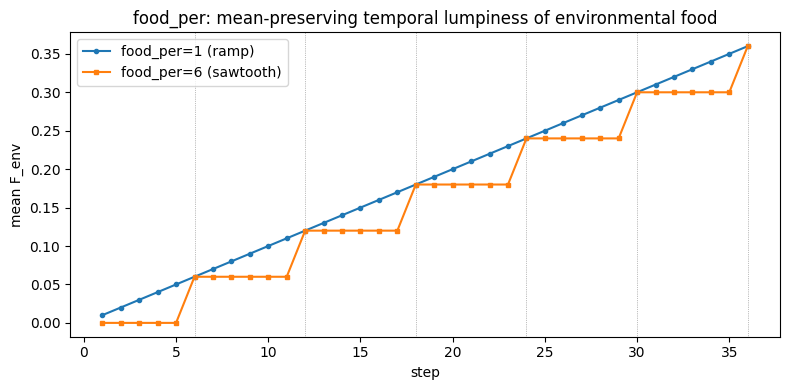

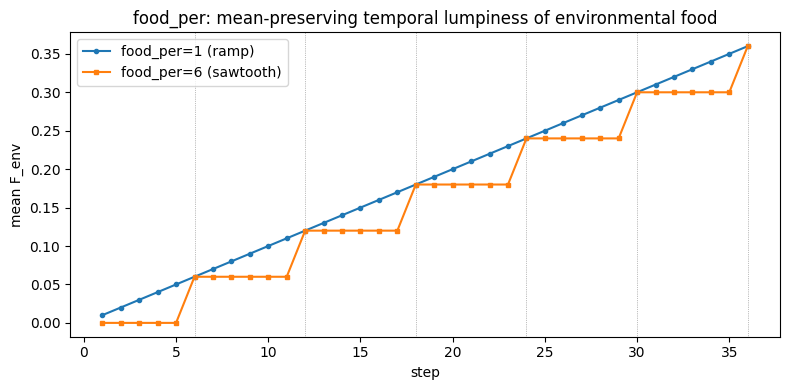

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, m1, '-o', ms=3, label='food_per=1 (ramp)')
ax.plot(t, mK, '-s', ms=3, label=f'food_per={K} (sawtooth)')
for x in t[period_ends]:
    ax.axvline(x, color='grey', lw=0.5, ls=':')
ax.set_xlabel('step'); ax.set_ylabel('mean F_env')
ax.set_title('food_per: mean-preserving temporal lumpiness of environmental food')
ax.legend(); fig.tight_layout()
fig

In [6]:
overall = test1_pass and test2_pass
print('=' * 44)
print('OVERALL:', 'PASS' if overall else 'FAIL')
print('=' * 44)
assert overall, 'resource-driving food_per demonstration FAILED'

OVERALL: PASS
